# 06 - Model comparison and Grad-CAM

**Owner:** Luiz Susin - CSC 7333 Group 6

This notebook compares the 4 methods. It draws upon the files created by other notebooks in the `results/metrics/` folder and applies Grad-CAM to highlight the areas of the face that each network focuses on.

Only models with both metrics and weights are used. This therefore allows the notebook to be executed as team-members complete their models. Copy the `.pt` files from Google Drive to the `models/` folder before running the Grad-CAM part.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
from torchvision import models

# Folders can be accessed whether the notebook is opened from the root of the repository or from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"
FIG = RESULTS_DIR / "figures"
TABLES = RESULTS_DIR / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

CLASSES = ["Neutral", "Happiness", "Surprise", "Sadness", "Anger", "Fear"]
SEED = 42
PRETTY_NAMES = {"hog_svm": "HOG + SVM", "cnn_scratch": "CNN (scratch)", "resnet18": "ResNet-18",
                "efficientnet_b0": "EfficientNet-B0"}
sns.set_theme(style="whitegrid")

In [2]:
# Output metric files generated by notebooks 02 to 05. The sequence of files is always the same.
results = {}
for name in PRETTY_NAMES:
    path = RESULTS_DIR / "metrics" / f"{name}.json"
    if path.exists():
        results[name] = json.loads(path.read_text())
print("results found for:", [PRETTY_NAMES[m] for m in results])

results found for: ['HOG + SVM', 'CNN (scratch)', 'ResNet-18', 'EfficientNet-B0']


## 1. Overall comparison

As the two main classes (Neutral and Happiness) constitute 64% of the test set, accuracy is heavily influenced by these. Models are therefore ordered by **macro F1** score which treats all 6 classes as equivalent. The "*clean*" columns relate only to test images which do not also appear in the training set (see notebook 01).

In [3]:
rows = []
for name, r in results.items():
    t, c = r["test"], r.get("test_clean", {})
    rows.append({
        "model": PRETTY_NAMES[name],
        "accuracy": t["accuracy"],
        "macro F1": t["macro_f1"],
        "macro precision": t["macro_precision"],
        "macro recall": t["macro_recall"],
        "clean accuracy": c.get("accuracy", np.nan),
        "clean macro F1": c.get("macro_f1", np.nan),
        "parameters (M)": r.get("parameters", np.nan) / 1e6 if r.get("parameters") else np.nan,
        "train time (min)": r.get("train_time_sec", np.nan) / 60,
        "ms / image": r.get("inference_ms_per_image", np.nan),
    })
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(RESULTS_DIR / "comparison.csv", float_format="%.4f")
comparison.style.format(precision=3).highlight_max(
    subset=["accuracy", "macro F1", "clean accuracy", "clean macro F1"], color="#cde8cd")

,accuracy,macro F1,macro precision,macro recall,clean accuracy,clean macro F1,parameters (M),train time (min),ms / image
model,,,,,,,,,
HOG + SVM,0.708,0.631,0.679,0.605,0.692,0.596,nan,3.377,4.235
CNN (scratch),0.836,0.790,0.774,0.814,0.830,0.781,4.819,42.228,0.499
ResNet-18,0.875,0.831,0.839,0.830,0.872,0.825,11.180,31.577,1.306
EfficientNet-B0,0.859,0.808,0.807,0.814,0.854,0.797,4.015,24.552,1.368


In [4]:
# The same table in LaTeX format. This facilitates the inclusion of up-to-date data in a write-up.
latex_cols = ["accuracy", "macro F1", "macro precision", "macro recall", "clean accuracy", "clean macro F1"]
latex = (comparison[latex_cols].reset_index().style.hide(axis="index")
         .format(precision=3, subset=latex_cols)
         .highlight_max(subset=latex_cols, props="bfseries: ;")
         .to_latex(hrules=True, column_format="l" + "c" * len(latex_cols)))
(TABLES / "comparison.tex").write_text(latex)
print(latex)

\begin{tabular}{lcccccc}
\toprule
model & accuracy & macro F1 & macro precision & macro recall & clean accuracy & clean macro F1 \\
\midrule
HOG + SVM & 0.708 & 0.631 & 0.679 & 0.605 & 0.692 & 0.596 \\
CNN (scratch) & 0.836 & 0.790 & 0.774 & 0.814 & 0.830 & 0.781 \\
ResNet-18 & \bfseries 0.875 & \bfseries 0.831 & \bfseries 0.839 & \bfseries 0.830 & \bfseries 0.872 & \bfseries 0.825 \\
EfficientNet-B0 & 0.859 & 0.808 & 0.807 & 0.814 & 0.854 & 0.797 \\
\bottomrule
\end{tabular}



## 2. Per-class F1

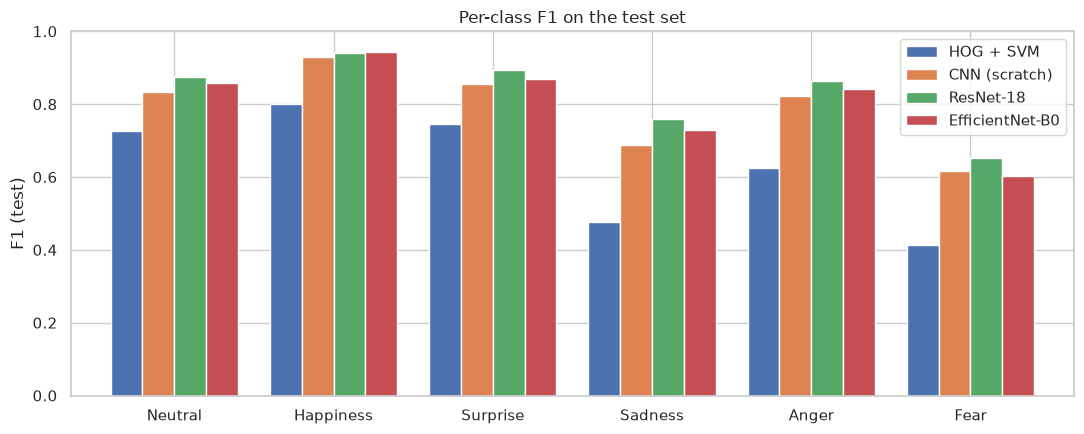

,HOG + SVM,CNN (scratch),ResNet-18,EfficientNet-B0
Neutral,0.728,0.832,0.875,0.859
Happiness,0.799,0.929,0.939,0.942
Surprise,0.747,0.855,0.895,0.870
Sadness,0.475,0.688,0.760,0.730
Anger,0.625,0.822,0.865,0.841
Fear,0.413,0.615,0.652,0.603


In [5]:
per_class = pd.DataFrame({
    PRETTY_NAMES[name]: {cls: m["f1"] for cls, m in r["test"]["per_class"].items()}
    for name, r in results.items()
})
fig, ax = plt.subplots(figsize=(11, 4.5))
per_class.plot.bar(ax=ax, width=0.8)
ax.set_ylabel("F1 (test)")
ax.set_ylim(0, 1)
ax.set_title("Per-class F1 on the test set")
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(FIG / "per_class_f1.png", dpi=150)
plt.show()

per_class_table = per_class.round(3)
per_class_table.style.format(precision=3).highlight_max(axis=1, props="bfseries: ;").to_latex(
    TABLES / "per_class_f1.tex", hrules=True, column_format="l" + "c" * per_class_table.shape[1])
per_class_table

## 3. Confusion matrices

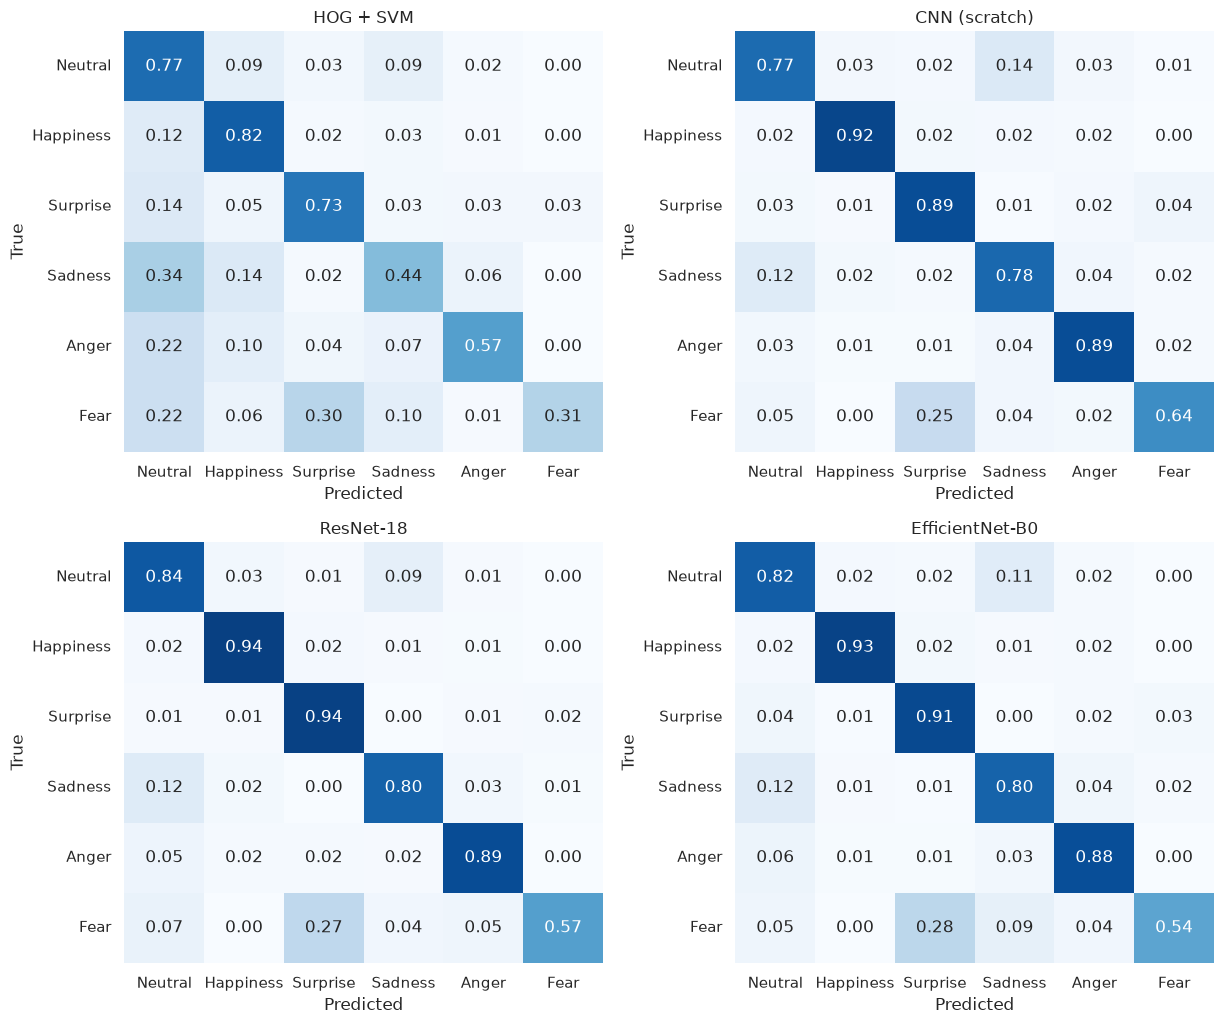

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12.4, 10.4))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    cm = np.array(r["test"]["confusion_matrix"])
    # Each row is divided by its sum. Diagonal entries then indicate the recall for each class.
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set(xlabel="Predicted", ylabel="True", title=PRETTY_NAMES[name])
plt.tight_layout()
fig.savefig(FIG / "confusion_all.png", dpi=150)
plt.show()

## 4. Training curves of the neural networks

Macro F1 on the validation set every epoch. For the pretrained models, the initial epochs correspond to training only the model head.

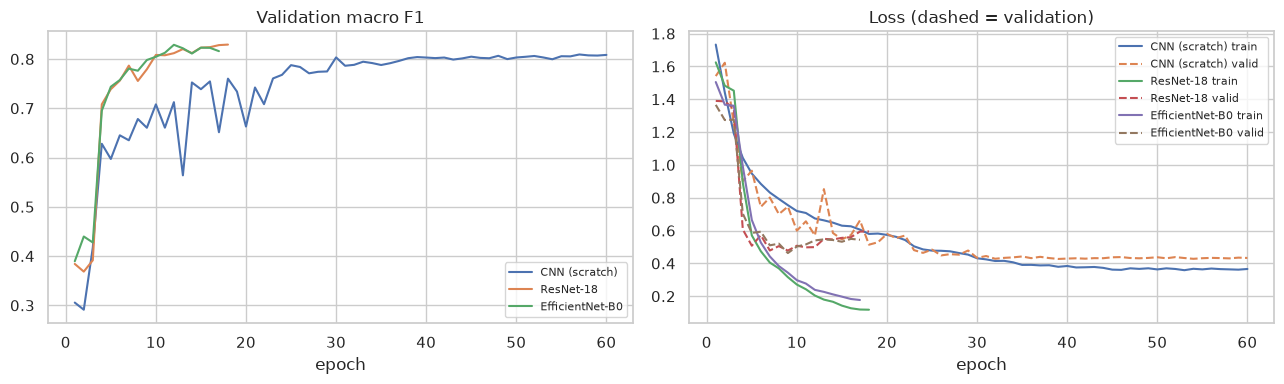

In [7]:
curves = {name: r["history"] for name, r in results.items() if "history" in r}
if curves:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, h in curves.items():
        epochs = np.arange(1, len(h["val_macro_f1"]) + 1)
        axes[0].plot(epochs, h["val_macro_f1"], label=PRETTY_NAMES[name])
        axes[1].plot(epochs, h["train_loss"], label=f"{PRETTY_NAMES[name]} train")
        axes[1].plot(epochs, h["val_loss"], "--", label=f"{PRETTY_NAMES[name]} valid")
    axes[0].set_title("Validation macro F1")
    axes[1].set_title("Loss (dashed = validation)")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(FIG / "training_curves_all.png", dpi=150)
    plt.show()
else:
    print("No neural network results yet.")

## 5. Grad-CAM

Grad-CAM (Selvaraju et al., 2017) finds the gradient of a class score in relation to final convolutional feature maps. It then applies this to the feature maps and produces a (rough) heatmap showing which areas were influential in achieving that class score. We anticipate that the eyes, eyebrows and mouth will be highlighted.

In [ ]:
def load_split(split, size=48):
    # Images and classes for one split. Excludes Disgust and Contempt. As the 224x224 training data exceeds 1 GB,
    # memory mapping is used. Only the selected images are then copied.
    names = np.load(DATA_DIR / f"FER2013{split}_labels.npy")
    images = np.load(DATA_DIR / f"FER2013{split}_{size}_images.npy", mmap_mode="r")
    keep = np.isin(names, CLASSES)
    labels = np.array([CLASSES.index(name) for name in names[keep]])
    return np.ascontiguousarray(images[keep]), labels


class ScratchCNN(nn.Module):
    # A VGG-type network for 48x48 grayscale faces. Each of the four sections halves the image size (48, 24, 12, 6,
    # 3) and doubles the number of filters. Global average pooling followed by a compact fully-connected section
    # produces the 6 class scores.
    def __init__(self, base_filters=64, dropout=0.4, block_dropout=0.25):
        super().__init__()
        blocks, in_ch = [], 1
        for out_ch in [base_filters, base_filters * 2, base_filters * 4, base_filters * 8]:
            blocks.append(nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                nn.MaxPool2d(2), nn.Dropout(block_dropout)))
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(in_ch, 256), nn.ReLU(inplace=True),
                                        nn.Dropout(dropout), nn.Linear(256, len(CLASSES)))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


def load_network(name):
    # Restore a network from the checkpoints of notebooks 03 to 05.
    checkpoint = torch.load(MODELS_DIR / f"{name}.pt", map_location="cpu")
    if name == "cnn_scratch":
        model = ScratchCNN(**checkpoint["model_kwargs"])
    elif name == "resnet18":
        model = models.resnet18()
        model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, len(CLASSES)))
    else:
        model = models.efficientnet_b0()
        model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, len(CLASSES)))
    model.load_state_dict(checkpoint["state_dict"])
    return model.eval()


def to_tensor(images, pretrained):
    # Convert the uint8 faces with shape (N, H, W) to the normalized float batch used to train the networks. For
    # the ImageNet networks, the gray channel is repeated 3 times and scaled using the ImageNet mean and standard
    # deviation.
    x = torch.from_numpy(images).unsqueeze(1).float() * (1 / 255)
    if not pretrained:
        return (x - 0.5) / 0.5
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return (x.repeat(1, 3, 1, 1) - mean) / std


def grad_cam(model, layer, x):
    # Grad-CAM (Selvaraju et al., 2017). Taking the derivative of the predicted class score with respect to the
    # final convolutional block feature maps produces a weighting for each feature map. The positive part of the
    # weighted sum of these maps is the heatmap.
    saved = {}
    hook = layer.register_forward_hook(lambda module, inputs, output: saved.update(maps=output))
    logits = model(x)
    hook.remove()
    pred = int(logits.argmax(1))
    grads = torch.autograd.grad(logits[0, pred], saved["maps"])[0]
    cam = torch.relu((grads.mean(dim=(2, 3), keepdim=True) * saved["maps"]).sum(dim=1))[0].detach().numpy()
    cam = cam - cam.min()
    return pred, cam / cam.max() if cam.max() > 0 else cam


def overlay(gray, cam):
    # Overlay the heatmap (blue for low, red for high) onto a grayscale face.
    heat = cv2.applyColorMap(np.uint8(255 * cv2.resize(cam, gray.shape[::-1])), cv2.COLORMAP_JET)
    return np.uint8(0.55 * cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB) + 0.45 * cv2.cvtColor(heat, cv2.COLOR_BGR2RGB))


networks = {name: load_network(name) for name in ["cnn_scratch", "resnet18", "efficientnet_b0"]}
x48, y_test = load_split("Test", 48)
x224, _ = load_split("Test", 224)


def explain(name, idx):
    # Output class and Grad-CAM overlay for one test image.
    pretrained = name != "cnn_scratch"
    image = x224[idx] if pretrained else x48[idx]
    model = networks[name]
    layer = model.layer4[-1] if name == "resnet18" else model.features[-1]
    pred, cam = grad_cam(model, layer, to_tensor(image[None], pretrained))
    return pred, overlay(image, cam)

networks with weights in models/: ['CNN (scratch)', 'ResNet-18', 'EfficientNet-B0']


### One test image per class

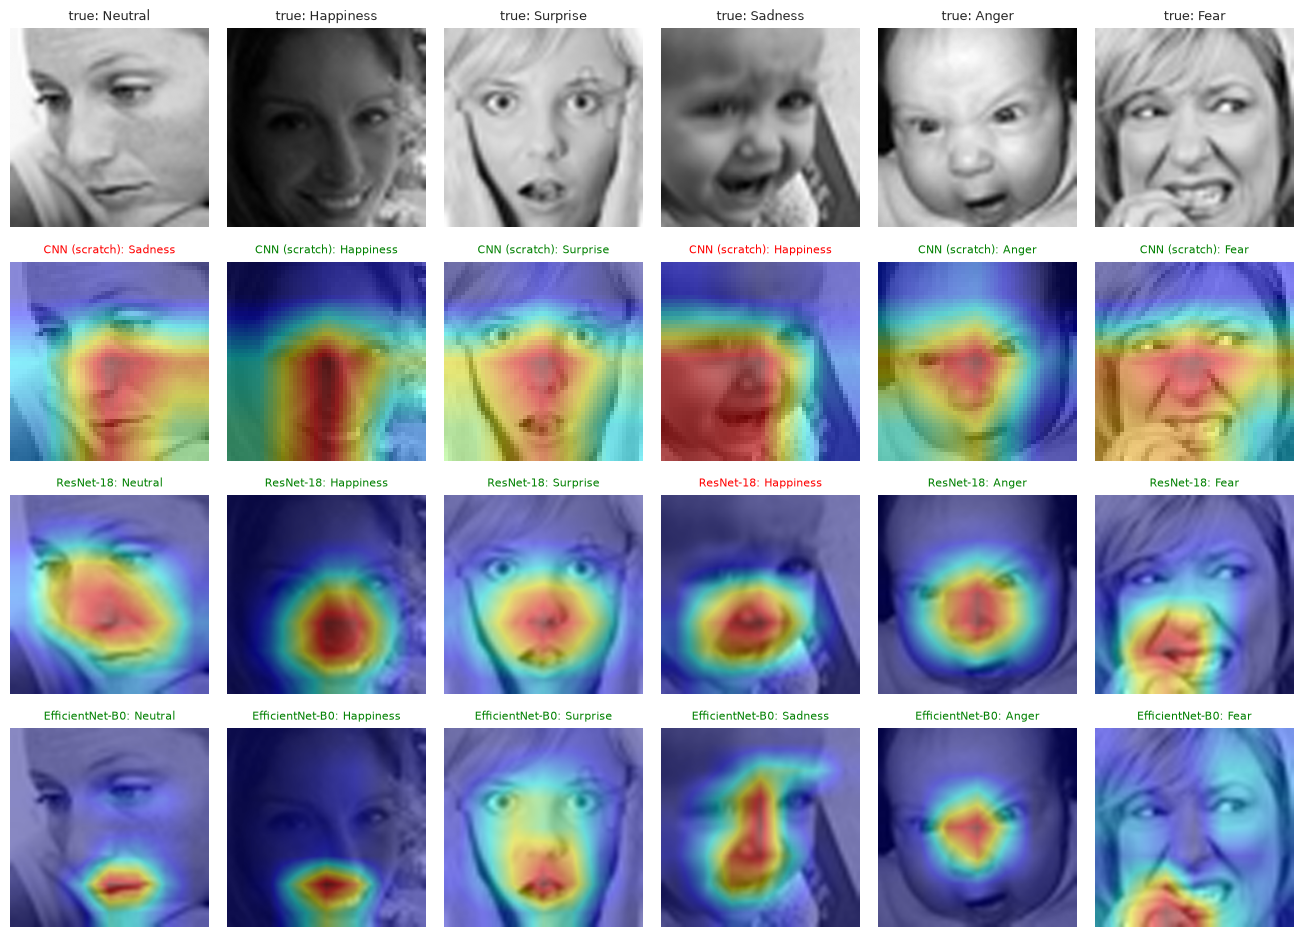

In [9]:
rng = np.random.default_rng(SEED)
picks = [rng.choice(np.flatnonzero(y_test == c)) for c in range(len(CLASSES))]
fig, axes = plt.subplots(len(networks) + 1, len(picks), figsize=(2.2 * len(picks), 2.4 * (len(networks) + 1)))
for j, idx in enumerate(picks):
    axes[0, j].imshow(x224[idx], cmap="gray")
    axes[0, j].set_title(f"true: {CLASSES[y_test[idx]]}", fontsize=9)
    for i, name in enumerate(networks, start=1):
        pred, vis = explain(name, idx)
        axes[i, j].imshow(vis)
        color = "green" if pred == y_test[idx] else "red"
        axes[i, j].set_title(f"{PRETTY_NAMES[name]}: {CLASSES[pred]}", fontsize=8, color=color)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG / "gradcam_per_class.png", dpi=150)
plt.show()

### Where the best network goes wrong

Misclassified test images from the model with the best macro F1, along with the heatmap relating to the (erroneous) class that was predicted.

best network: ResNet-18


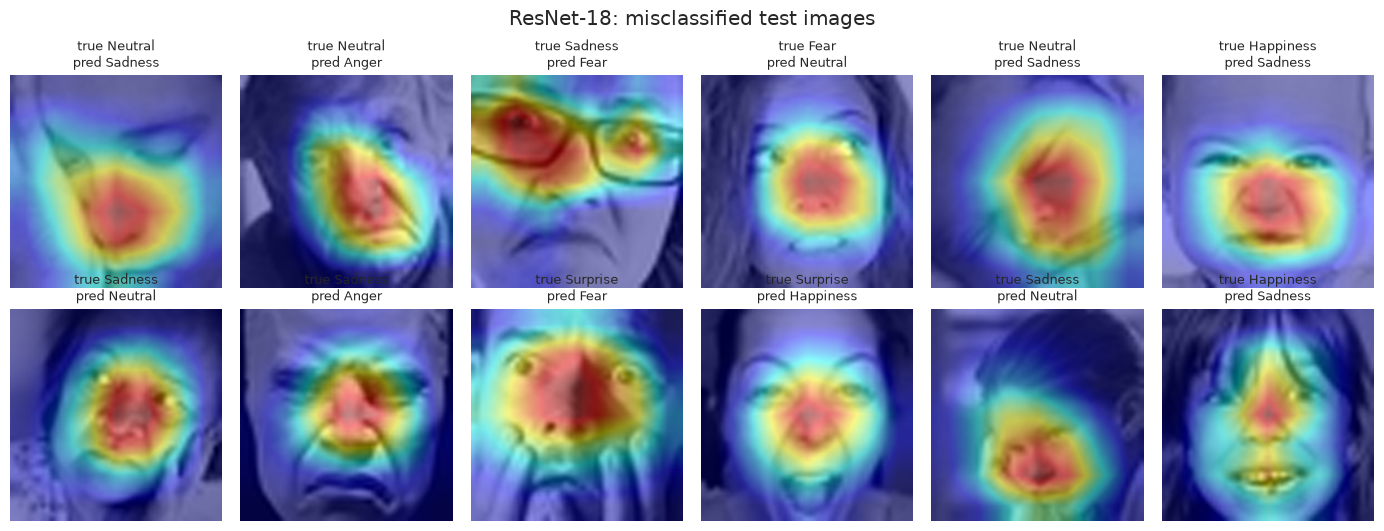

In [10]:
best = max(networks, key=lambda m: results[m]["test"]["macro_f1"])
print("best network:", PRETTY_NAMES[best])
rng = np.random.default_rng(SEED + 1)
errors = []
for idx in rng.permutation(len(y_test)):
    pred, vis = explain(best, idx)
    if pred != y_test[idx]:
        errors.append((idx, pred, vis))
    if len(errors) == 12:
        break
fig, axes = plt.subplots(2, 6, figsize=(14, 5.4))
for ax, (idx, pred, vis) in zip(axes.ravel(), errors):
    ax.imshow(vis)
    ax.set_title(f"true {CLASSES[y_test[idx]]}\npred {CLASSES[pred]}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"{PRETTY_NAMES[best]}: misclassified test images")
plt.tight_layout()
fig.savefig(FIG / "gradcam_errors.png", dpi=150)
plt.show()

## 6. Takeaways

_To be filled in after all 4 models have been trained:_

- _By what margin (both in macro F1 and in accuracy) is transfer learning more effective than HOG+SVM and the scratch CNN?_
- _Which classes are most positively affected by transfer learning (perhaps Fear and/or Sadness)? What continuing confusions are there?_
- _Is the additional expense (in terms of parameters, together with training and inference times) justified?_
- _Do Grad-CAM heatmaps highlight primarily the eyes, brows and mouth or other elements such as the background and hair?_